# 05 - Second-order linear equations: superposition, the Wronskian, Abel's theorem

**MATH 331 - Differential Equations.** Lecture plan: Session 11 (Unit 5: linear independence, the Wronskian, superposition).

**References**
* J. Lebl, *Notes on Diffy Qs*: **Section 2.1** (Theorems 2.1.1-2.1.3; the example
  $y'' - 2x^{-2}y = 0$; linear independence; Exercises 2.1.1 and 2.1.7). The course text does not
  use the Wronskian: for two functions it tests independence by asking whether one is a constant
  multiple of the other.
* W.A. Adkins and M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012): **Section
  3.2** (the Wronskian), **Section 3.3** (Theorem 8, Abel's formula; Exercise 17), **Section 5.2**
  (Theorem 5, Abel's formula with variable coefficients; Example 7).
* Exercise numbers are those of the lists at the end of each chapter.
* Related notebooks: 08 and video R08 (linear systems), video R07 (determinants), 11 (existence
  and uniqueness), 06 (the characteristic equation), **05E** (optional).

**What you will learn**
1. Why the solutions of a linear homogeneous equation can be added and scaled (superposition).
2. Why **two** solutions are enough to write all of them, and which two will do.
3. The **Wronskian**: a 2 x 2 determinant that tells whether two solutions will do.
4. **Abel's theorem**: the Wronskian can be found without solving the equation.
5. How one solution gives a second one (reduction of order).

## 1. Theory in brief

**The equation.** A second-order linear equation, in standard form (coefficient of $y''$ equal to
1), and *homogeneous* (zero on the right):

$$ y'' + p(x)\,y' + q(x)\,y = 0 . $$

**Superposition** (Lebl, Theorem 2.1.1). If $y_1$ and $y_2$ are solutions, so is
$C_1y_1 + C_2y_2$ for any constants.

**Existence and uniqueness** (Lebl, Theorem 2.1.2). If $p$ and $q$ are continuous on an interval
containing $x_0$, there is exactly one solution with $y(x_0) = y_0$, $y'(x_0) = v_0$, and it
lives on the whole interval. Two conditions, because the equation is of second order.

**Linear independence.** Two functions are *independent* when neither is a constant multiple of
the other.

**The general solution** (Lebl, Theorem 2.1.3). If $y_1, y_2$ are two **independent** solutions,
every solution is $y = C_1y_1 + C_2y_2$.

**The Wronskian** (Adkins and Davidson, Section 3.2):

$$ W[y_1, y_2] = \det\begin{pmatrix} y_1 & y_2 \\ y_1' & y_2' \end{pmatrix} = y_1\,y_2' - y_1'\,y_2 . $$

For two solutions of the equation: they are independent exactly when $W \ne 0$.

**Abel's theorem** (Adkins and Davidson, Sections 3.3 and 5.2). $\;W' = -p(x)\,W$, so

$$ W(x) = W(x_0)\,e^{-\int_{x_0}^{x} p(s)\,ds} : $$

the Wronskian of two solutions is either never zero or always zero, and it is known from $p$
alone.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: rk4, wronskian_values, check, check_formula).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp                      # noqa: F401  (not used in every notebook)
from IPython.display import Math, display                 # noqa: F401
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. Superposition

The example of Lebl (Section 2.1): $\;y'' - \dfrac{2}{x^2}\,y = 0$ for $x > 0$, with the two
solutions $y_1 = x^2$ and $y_2 = \dfrac1x$.

By hand: $(x^2)'' = 2$ and $\tfrac{2}{x^2}\,x^2 = 2$; $\;(1/x)'' = \tfrac{2}{x^3}$ and
$\tfrac{2}{x^2}\cdot\tfrac1x = \tfrac{2}{x^3}$. Both are solutions.

Now take **any** combination $C_1x^2 + C_2/x$. Because differentiating and multiplying by
$\tfrac{2}{x^2}$ are both linear operations, the left side of the equation is $C_1$ times zero
plus $C_2$ times zero: still a solution. That is superposition, and it is why linear equations
can be solved systematically.

It is **false for nonlinear equations**: $y = \dfrac{1}{1 - x}$ solves $y' = y^2$ (notebook 09),
but twice that function does not.

In [2]:
x = sp.symbols("x", positive=True)              # we work on the interval x > 0
C1, C2 = sp.symbols("C1 C2")


def residual(left, right=0):
    # left side minus right side of an equation, simplified: 0 for a solution (notebook 09)
    return sp.simplify(left - right)


def lebl_equation(y):
    # the left side of  y'' - 2 y / x^2 = 0  for a candidate y(x)
    return sp.diff(y, x, 2) - 2 * y / x ** 2


y1, y2 = x ** 2, 1 / x
print("x^2            :", residual(lebl_equation(y1)))
print("1/x            :", residual(lebl_equation(y2)))
print("C1 x^2 + C2 / x:", residual(lebl_equation(C1 * y1 + C2 * y2)))

u = sp.symbols("u")
one, two = 1 / (1 - u), 2 / (1 - u)             # the nonlinear equation y' = y^2
print("nonlinear, 1/(1 - x):", residual(sp.diff(one, u), one ** 2), "   twice it:", residual(sp.diff(two, u), two ** 2))

assert residual(lebl_equation(C1 * y1 + C2 * y2)) == 0
assert residual(sp.diff(two, u), two ** 2) != 0

x^2            : 0
1/x            : 0


C1 x^2 + C2 / x: 0
nonlinear, 1/(1 - x): 0    twice it: -2/(u - 1)**2


## 3. Do two solutions give *all* solutions?

Suppose we want the solution with $y(x_0) = y_0$ and $y'(x_0) = v_0$, and we try
$y = C_1y_1 + C_2y_2$. The two conditions are a **linear system** for $C_1$ and $C_2$ (notebook 08,
video R08):

$$ \begin{pmatrix} y_1(x_0) & y_2(x_0) \\ y_1'(x_0) & y_2'(x_0) \end{pmatrix}
\begin{pmatrix} C_1 \\ C_2 \end{pmatrix} = \begin{pmatrix} y_0 \\ v_0 \end{pmatrix} . $$

A 2 x 2 system has exactly one solution for **every** right-hand side when its determinant is
not zero (video R07). That determinant is the Wronskian at $x_0$.

**By hand**, for Lebl's example at $x_0 = 1$: $y_1 = x^2$, $y_1' = 2x$, $y_2 = 1/x$,
$y_2' = -1/x^2$, so

$$ C_1 + C_2 = y_0, \qquad 2C_1 - C_2 = v_0, \qquad \det = (1)(-1) - (2)(1) = -3 \ne 0 . $$

For example $y(1) = 2$, $y'(1) = 1$: adding the equations, $3C_1 = 3$; so $C_1 = 1$, $C_2 = 1$ and
$y = x^2 + \dfrac1x$.

Since any initial data can be matched, and a solution is fixed by its initial data
(uniqueness), **every** solution is of the form $C_1x^2 + C_2/x$.

**A pair that will not do:** $x^2$ and $3x^2$ are both solutions, but one is a multiple of the
other. The determinant is zero, and most initial data cannot be matched.

In [3]:
y0, v0 = sp.symbols("y0 v0")
X0 = 1


def constants_for(first, second, position, velocity):
    # C1, C2 such that C1 first + C2 second has y(X0) = position and y'(X0) = velocity
    combination = C1 * first + C2 * second
    return sp.solve([sp.Eq(combination.subs(x, X0), position),
                     sp.Eq(sp.diff(combination, x).subs(x, X0), velocity)], [C1, C2])


print("any data  :", constants_for(y1, y2, y0, v0))
print("y(1) = 2, y'(1) = 1:", constants_for(y1, y2, 2, 1))
print("with x^2 and 3x^2, any data:", constants_for(x ** 2, 3 * x ** 2, y0, v0), " (no solution)")

assert constants_for(y1, y2, 2, 1) == {C1: 1, C2: 1}
assert constants_for(x ** 2, 3 * x ** 2, y0, v0) == []

any data  : {C1: v0/3 + y0/3, C2: -v0/3 + 2*y0/3}
y(1) = 2, y'(1) = 1: {C1: 1, C2: 1}
with x^2 and 3x^2, any data: []  (no solution)


## 4. The Wronskian

$$ W[y_1, y_2] = y_1\,y_2' - y_1'\,y_2 . $$

Three computations by hand:

* $W[x^2,\ 1/x] = x^2\cdot\big(-\tfrac{1}{x^2}\big) - 2x\cdot\tfrac1x = -1 - 2 = -3$;
* $W[e^{x},\ e^{2x}] = e^{x}\cdot 2e^{2x} - e^{x}\cdot e^{2x} = e^{3x}$ (Lebl, Exercise 2.1.1 asks to
  show that these two are independent);
* $W[\cos x,\ \sin x] = \cos^2x + \sin^2x = 1$.

None of them is zero: each pair is independent. For a pair of multiples, such as $x^2$ and
$3x^2$, the two columns of the determinant are proportional and $W = 0$.

**The link with Lebl's test.** Where $y_1 \ne 0$, the quotient rule gives
$\;\Big(\dfrac{y_2}{y_1}\Big)' = \dfrac{W}{y_1^2}$. So $W = 0$ exactly when the ratio $y_2/y_1$ is
constant: when one function is a constant multiple of the other. The Wronskian measures how fast
the ratio changes.

(A warning for functions that are **not** solutions of the same equation is in the optional
notebook 05E.)

In [4]:
def wronskian_of(first, second, variable=x):
    return sp.simplify(first * sp.diff(second, variable) - sp.diff(first, variable) * second)


PAIRS = (("x^2, 1/x", x ** 2, 1 / x),
         ("e^x, e^(2x)", sp.exp(x), sp.exp(2 * x)),
         ("cos x, sin x", sp.cos(x), sp.sin(x)),
         ("x^2, 3x^2", x ** 2, 3 * x ** 2))

for name, first, second in PAIRS:
    print(f"W[{name}] = {wronskian_of(first, second)}")

assert wronskian_of(x ** 2, 1 / x) == -3 and wronskian_of(x ** 2, 3 * x ** 2) == 0
assert residual(sp.diff(y2 / y1, x), wronskian_of(y1, y2) / y1 ** 2) == 0       # the ratio formula

W[x^2, 1/x] = -3
W[e^x, e^(2x)] = exp(3*x)
W[cos x, sin x] = 1
W[x^2, 3x^2] = 0


## 5. Abel's theorem

> **Theorem** (Adkins and Davidson, Section 3.3, Theorem 8, and Section 5.2, Theorem 5). Let $p$
> and $q$ be continuous on an interval, and $y_1, y_2$ two solutions of
> $y'' + p(x)\,y' + q(x)\,y = 0$ there. Then
> $$ W(x) = W(x_0)\,\exp\Big(-\int_{x_0}^{x} p(s)\,ds\Big) . $$
> So $W$ is either never zero or always zero on the interval.

**The proof is three lines**, and worth knowing. Differentiate $W = y_1y_2' - y_1'y_2$; the terms
$y_1'y_2'$ cancel:

$$ W' = y_1\,y_2'' - y_1''\,y_2 . $$

Use the equation, $y'' = -p\,y' - q\,y$, for both solutions; the terms with $q$ cancel:

$$ W' = y_1\,(-p\,y_2' - q\,y_2) - (-p\,y_1' - q\,y_1)\,y_2 = -p\,(y_1y_2' - y_1'y_2) = -p\,W . $$

So $W$ itself solves a first-order equation, $W' = -p(x)\,W$: separable and linear (notebooks 10
and 11), with the solution written in the theorem. An exponential is never zero. $\square$

**What it gives.**

1. For solutions, checking $W$ at **one** point decides independence on the whole interval.
2. $W$ is known **without solving** the equation: only $p$ is needed, and remember to put the
   equation in standard form first.
3. If there is no $y'$ term ($p = 0$), the Wronskian is constant.
4. For constant coefficients, $a y'' + b y' + c y = 0$: $p = b/a$ and $W = K\,e^{-bx/a}$.

Four checks: the Wronskian computed from known solutions, against Abel's formula.

In [5]:
s = sp.symbols("s", positive=True)
w = sp.symbols("omega", positive=True)


def abel_check(name, p, solutions, x_start):
    # W from the two solutions, and from Abel's formula W(x_start) exp(-integral of p)
    direct = wronskian_of(*solutions)
    predicted = sp.simplify(direct.subs(x, x_start) * sp.exp(-sp.integrate(p.subs(x, s), (s, x_start, x))))
    agree = sp.simplify(direct - predicted) == 0
    print(f"{name}\n    p = {p},   W = {direct},   Abel: {predicted},   agree: {agree}")
    return agree


checks = (
    abel_check("Lebl 2.1:  y'' - 2 y / x^2 = 0", sp.Integer(0), (x ** 2, 1 / x), 1),
    abel_check("oscillator:  y'' + omega^2 y = 0", sp.Integer(0), (sp.cos(w * x), sp.sin(w * x)), 1),
    abel_check("Adkins-Davidson 5.2, Example 7:  x^2 y'' + x y' + y = 0", 1 / x,
               (sp.cos(sp.log(x)), sp.sin(sp.log(x))), 1),
    abel_check("damped oscillator:  y'' + 2 y' + 5 y = 0", sp.Integer(2),
               (sp.exp(-x) * sp.cos(2 * x), sp.exp(-x) * sp.sin(2 * x)), 1),
)
assert all(checks)

Lebl 2.1:  y'' - 2 y / x^2 = 0
    p = 0,   W = -3,   Abel: -3,   agree: True
oscillator:  y'' + omega^2 y = 0
    p = 0,   W = omega,   Abel: omega,   agree: True


Adkins-Davidson 5.2, Example 7:  x^2 y'' + x y' + y = 0
    p = 1/x,   W = 1/x,   Abel: 1/x,   agree: True


damped oscillator:  y'' + 2 y' + 5 y = 0
    p = 2,   W = 2*exp(-2*x),   Abel: 2*exp(-2*x),   agree: True


**A case where we know neither solution.** $\;y'' + \dfrac{\alpha}{1 + x}\,y' + y = 0$. For most
values of $\alpha$ (for example $\alpha = 1$) there is no formula in elementary functions for its
solutions, but Abel's theorem gives their Wronskian at once:

$$ W(x) = W(0)\,\exp\Big(-\int_0^x \frac{\alpha}{1 + s}\,ds\Big) = \frac{W(0)}{(1 + x)^{\alpha}} . $$

We compute two solutions numerically (RK4, notebook 04), starting from $y_1(0) = 1$,
$y_1'(0) = 0$ and $y_2(0) = 0$, $y_2'(0) = 1$, so that $W(0) = 1$; then we form $W$ from the
numbers and compare.

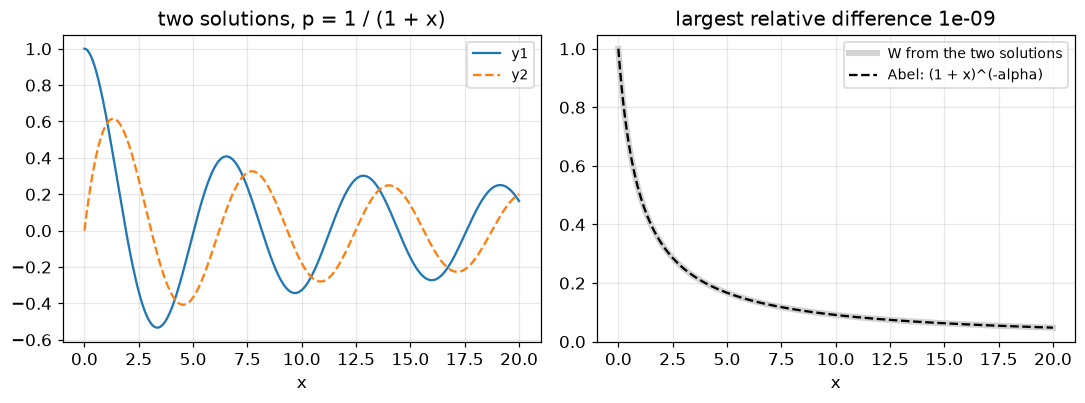

In [6]:
TWO_PANELS = (10.0, 3.8)
STEP = 0.01
DEFAULT_ALPHA, DEFAULT_LENGTH = 1.0, 20.0


def two_solutions(alpha, x_end):
    # two numerical solutions of y'' + alpha / (1 + x) y' + y = 0, their Wronskian, and Abel's prediction
    def system(point, state):                   # state = (y1, y1', y2, y2')
        p = alpha / (1 + point)
        return np.array([state[1], -p * state[1] - state[0], state[3], -p * state[3] - state[2]])

    points, values = ol.rk4(system, (0.0, x_end), [1.0, 0.0, 0.0, 1.0], STEP)
    computed = ol.wronskian_values(values[:, 0], values[:, 1], values[:, 2], values[:, 3])
    return points, values, computed, (1 + points) ** (-alpha)


def abel_numeric(alpha=DEFAULT_ALPHA, x_end=DEFAULT_LENGTH):
    points, values, computed, predicted = two_solutions(alpha, x_end)
    fig, (left, right) = plt.subplots(1, 2, figsize=TWO_PANELS)
    left.plot(points, values[:, 0], "-", label="y1")
    left.plot(points, values[:, 2], "--", label="y2")
    left.set_xlabel("x")
    left.set_title(f"two solutions, p = {alpha:g} / (1 + x)")
    left.legend(loc="upper right")
    right.plot(points, computed, "-", linewidth=4, color="lightgray", label="W from the two solutions")
    right.plot(points, predicted, "--", color="black", label="Abel: (1 + x)^(-alpha)")
    right.set_xlabel("x")
    right.set_title(f"largest relative difference {np.max(np.abs(computed / predicted - 1)):.0e}")
    right.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


abel_numeric()
points, values, computed, predicted = two_solutions(DEFAULT_ALPHA, DEFAULT_LENGTH)
assert np.max(np.abs(computed / predicted - 1)) < 1e-6

*The plot shows* two panels. Left: the two numerical solutions, both oscillating with an
amplitude that slowly decreases; $y_1$ (solid) starts from 1 and $y_2$ (dashed) from 0. Right:
their Wronskian (thick grey line), which falls smoothly from 1 like $1/(1 + x)$, with Abel's
prediction (black dashes) exactly on top of it. The two solutions wiggle; their Wronskian does
not.

**Sliders.** Answer *before* moving $\alpha$:

1. For $\alpha = 0$ (no $y'$ term), what is the Wronskian?
2. For a negative $\alpha$, does the Wronskian grow or shrink?

In [7]:
ALPHA_RANGE = (-1.0, 3.0, 0.25)             # minimum, maximum, step
LENGTH_RANGE = (5.0, 40.0, 5.0)

interact(abel_numeric,
         alpha=FloatSlider(value=DEFAULT_ALPHA, min=ALPHA_RANGE[0], max=ALPHA_RANGE[1], step=ALPHA_RANGE[2],
                           description="alpha", continuous_update=False),
         x_end=FloatSlider(value=DEFAULT_LENGTH, min=LENGTH_RANGE[0], max=LENGTH_RANGE[1], step=LENGTH_RANGE[2],
                           description="x max", continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='alpha', max=3.0, min=-1.0, ...

(1: constant, equal to 1. 2: it grows, like $(1 + x)^{|\alpha|}$: the formula holds for either
sign of $p$.)

## 6. A second solution from a first one

Abel's theorem and the ratio formula of Section 4 give a recipe, called **reduction of order**
(Lebl, Exercise 2.1.7). If $y_1$ is known, then $\Big(\dfrac{y_2}{y_1}\Big)' = \dfrac{W}{y_1^2}$
with $W = e^{-\int p\,dx}$ (taking the constant equal to 1), and integrating:

$$ \boxed{\;y_2(x) = y_1(x)\int \frac{e^{-\int p\,dx}}{y_1(x)^2}\,dx\;} $$

**By hand: a repeated root** (a preview of notebook 06). $y'' - 2r\,y' + r^2 y = 0$ has the
solution $y_1 = e^{rx}$, and no second exponential. Here $p = -2r$, so $e^{-\int p} = e^{2rx}$, and

$$ y_2 = e^{rx}\int \frac{e^{2rx}}{e^{2rx}}\,dx = x\,e^{rx} . $$

The function below does these two integrals.

In [8]:
r = sp.symbols("r", real=True)


def second_solution(first, p):
    # reduction of order: first * integral( exp(-integral of p) / first^2 ), constants omitted
    abel = sp.exp(-sp.integrate(p, x))
    return sp.simplify(first * sp.integrate(sp.simplify(abel / first ** 2), x))


repeated = second_solution(sp.exp(r * x), -2 * r)
print("repeated root: y2 =", repeated)
assert residual(repeated, x * sp.exp(r * x)) == 0
assert residual(sp.diff(repeated, x, 2) - 2 * r * sp.diff(repeated, x) + r ** 2 * repeated) == 0

repeated root: y2 = x*exp(r*x)


## 7. Exercises

Final answers are at the end; try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

Which of these pairs are linearly independent? (Is one a constant multiple of the other?) Type
`True` for independent, in a list.

1. $e^{x}$ and $e^{2x}$
2. $x$ and $2x$
3. $\cos x$ and $\sin x$
4. $e^{x}$ and $e^{x + 1}$

In [9]:
my_independent = None           # for example [True, True, True, True]
# ---- your answers go above this line; the lines below check them (nothing to change) ----

ol.check("Exercise 1", my_independent, [True, False, True, False]);

Exercise 1: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

**(a)** *Adkins and Davidson, Section 3.3, Exercise 17.* The functions $e^{3t}$ and $e^{-7t}$ are
solutions of an equation $y'' + b\,y' + c\,y = 0$. Find $b$ and $c$ (each exponential $e^{rt}$
must satisfy $r^2 + br + c = 0$). Then compute their Wronskian by hand: it has the form
$K\,e^{-bt}$. Give $K$.

**(b)** Without solving, find the Wronskian of two solutions of
$\;x\,y'' + 2y' + x\,y = 0$ ($x > 0$) with $W(1) = 1$. (Standard form first!) Type it as a formula
in `x`.

**(c)** For Lebl's equation of Section 2, find $C_1$ and $C_2$ such that $y = C_1x^2 + C_2/x$ has
$y(1) = 0$ and $y'(1) = 3$.

In [10]:
my_b_and_c = None               # (a): [b, c]
my_K = None                     # (a)
my_wronskian = None             # (b): a formula in x
my_constants = None             # (c): [C1, C2]
# ---- your answers go above this line; the lines below check them (nothing to change) ----

t = sp.symbols("t")
pair = (sp.exp(3 * t), sp.exp(-7 * t))
expected_K = wronskian_of(*pair, variable=t).subs(t, 0)             # the Wronskian at t = 0 is K
found = constants_for(y1, y2, 0, 3)
X_INTERVAL = (0.5, 3.0)

ol.check("Exercise 2a, b and c", my_b_and_c, [4, -21])
ol.check("Exercise 2a, K", my_K, float(expected_K))
ol.check_formula("Exercise 2b", my_wronskian, 1 / x ** 2, x, X_INTERVAL)
ol.check("Exercise 2c", my_constants, [float(found[C1]), float(found[C2])]);

Exercise 2a, b and c: no answer yet (replace None with your value)
Exercise 2a, K: no answer yet (replace None with your value)
Exercise 2b: no answer yet (replace None with your formula)
Exercise 2c: no answer yet (replace None with your value)


### Exercise 3 - Fill in

Complete the function `wronskian`, which returns the Wronskian of two SymPy expressions in `x`:
use `sp.diff(..., x)`, and `sp.simplify` on the result. The next cell tries it on the pairs of
Section 4.

In [11]:
def wronskian(first, second):
    return None                 # replace None with the formula

In [12]:
if wronskian(x, x) is None:
    print("Exercise 3: complete wronskian first")
else:
    for name, first, second in PAIRS:
        assert sp.simplify(wronskian(first, second) - wronskian_of(first, second)) == 0, f"wrong Wronskian for {name}"
    assert sp.simplify(wronskian(1 / x, x ** 2) - 3) == 0, "exchanging the two functions must change the sign"
    print(f"Exercise 3: correct on all {len(PAIRS)} pairs, and W[1/x, x^2] = {wronskian(1 / x, x ** 2)}")

Exercise 3: complete wronskian first


### Exercise 4 - Explore

The equation $\;x^2y'' - 3x\,y' + 4y = 0$ ($x > 0$) has the solution $y_1 = x^2$.

* Check it with `residual`.
* Put the equation in standard form: what is $p$?
* Find a second solution with `second_solution(y1, p)`, and check it too.
* Compute the Wronskian of the two solutions with `wronskian_of`, and compare with what Abel's
  theorem predicts from $p$ alone.
* Do the reduction of order by hand.

In [13]:
# your code here: for example second_solution(x**2, ...)

## 8. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. `[True, False, True, False]`. In the last pair $e^{x+1} = e\cdot e^{x}$: a constant multiple.
2. (a) $r = 3$ and $r = -7$ are the roots of $r^2 + 4r - 21$: $b = 4$, $c = -21$;
   $W = -10\,e^{-4t}$, so $K = -10$. (b) Standard form: $y'' + \tfrac2x y' + y = 0$, $p = \tfrac2x$,
   $W = e^{-2\ln x} = \dfrac{1}{x^2}$. (c) $C_1 + C_2 = 0$, $2C_1 - C_2 = 3$: $C_1 = 1$, $C_2 = -1$.
3. `return sp.simplify(first * sp.diff(second, x) - sp.diff(first, x) * second)`
4. $p = -\tfrac3x$; $y_2 = x^2\ln x$; $W = x^3$, and Abel gives $e^{\int 3/x} = x^3$.

</details>

**Where to go next:** notebook 06 (constant coefficients: the characteristic equation), and, if
you are curious, the optional notebook 05E (the Wronskian as an area, special functions, zeros
that take turns).